<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/cuckoo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

City Coordinates:
City 0: X=37.45, Y=95.07
City 1: X=73.20, Y=59.87
City 2: X=15.60, Y=15.60
City 3: X=5.81, Y=86.62
City 4: X=60.11, Y=70.81
City 5: X=2.06, Y=96.99
City 6: X=83.24, Y=21.23
City 7: X=18.18, Y=18.34
City 8: X=30.42, Y=52.48
City 9: X=43.19, Y=29.12

Initial Best Distance: 360.53
Iteration 20: Best Distance = 352.41
Iteration 40: Best Distance = 352.41
Iteration 60: Best Distance = 352.41
Iteration 80: Best Distance = 352.41
Iteration 100: Best Distance = 352.41
Iteration 120: Best Distance = 352.41
Iteration 140: Best Distance = 330.10
Iteration 160: Best Distance = 322.08
Iteration 180: Best Distance = 322.08
Iteration 200: Best Distance = 322.08

       CUCKOO SEARCH RESULTS
Best Route:
0 -> 1 -> 4 -> 6 -> 9 -> 2 -> 7 -> 8 -> 3 -> 5 -> 0

Minimum Total Distance:
322.08

Number of Cities: 10
Number of Nests: 30
Number of Iterations: 200

Route Validation:
VALID: Every city is visited exactly once.
VALID: Route returns to starting city.


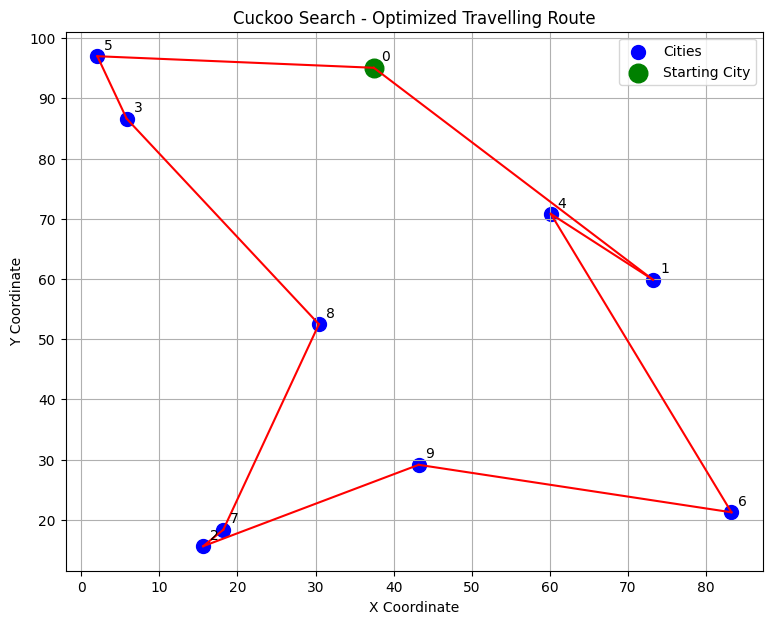

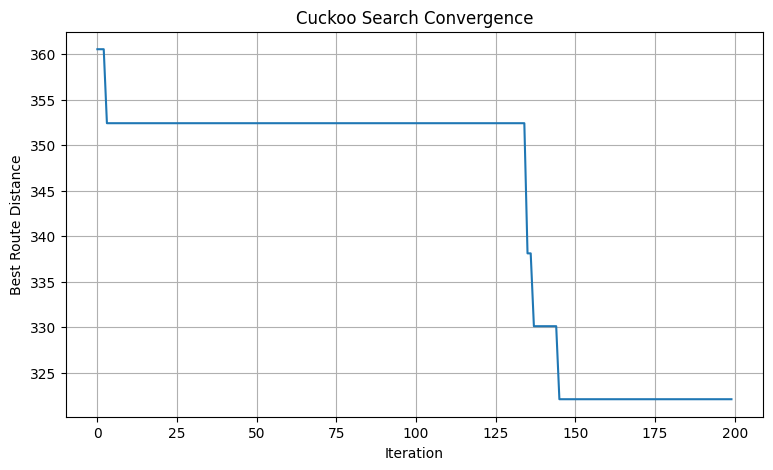


Route Distance Details:


,From City,To City,Distance
0,0,1,50.17
1,1,4,17.06
2,4,6,54.71
3,6,9,40.82
4,9,2,30.73
5,2,7,3.76
6,7,8,36.26
7,8,3,42.09
8,3,5,11.03
9,5,0,35.45


Total Distance: 322.08

Excel file created: Cuckoo_Search_TSP_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# CUCKOO SEARCH OPTIMIZATION (CSO) FOR TRAVELLING SALESPERSON
# PROBLEM (TSP)
# Google Colab - Complete Implementation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from math import gamma, sin, pi
from IPython.display import display

# ------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------

NUM_CITIES = 10
NUM_NESTS = 30
NUM_ITERATIONS = 200

PA = 0.25              # Probability of abandoning a nest
ALPHA = 0.15           # Lévy flight step-size scaling
BETA = 1.5             # Lévy distribution parameter

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# 2. GENERATE CITY LOCATIONS
# ------------------------------------------------------------

# Random 2D coordinates for each city
cities = np.random.rand(NUM_CITIES, 2) * 100

# Calculate Euclidean distance matrix
distance_matrix = np.zeros((NUM_CITIES, NUM_CITIES))

for i in range(NUM_CITIES):
    for j in range(NUM_CITIES):
        distance_matrix[i, j] = np.linalg.norm(
            cities[i] - cities[j]
        )

print("City Coordinates:")
for i, city in enumerate(cities):
    print(f"City {i}: X={city[0]:.2f}, Y={city[1]:.2f}")

# ------------------------------------------------------------
# 3. DECODE RANDOM KEYS INTO A VALID ROUTE
# ------------------------------------------------------------

# City 0 is always the starting city.
# The remaining cities are ordered using random keys.

def decode_route(keys):
    order = np.argsort(keys) + 1
    route = np.concatenate(([0], order, [0]))
    return route


# ------------------------------------------------------------
# 4. FITNESS FUNCTION
# ------------------------------------------------------------

# Objective: Minimize total travelling distance.

def calculate_distance(route):
    total_distance = 0

    for i in range(len(route) - 1):
        city_a = route[i]
        city_b = route[i + 1]

        total_distance += distance_matrix[city_a, city_b]

    return total_distance


def fitness(keys):
    route = decode_route(keys)
    return calculate_distance(route)


# ------------------------------------------------------------
# 5. LEVY FLIGHT USING MANTEGNA'S ALGORITHM
# ------------------------------------------------------------

def levy_flight(beta=1.5):
    numerator = (
        gamma(1 + beta) * sin(pi * beta / 2)
    )

    denominator = (
        gamma((1 + beta) / 2)
        * beta
        * 2 ** ((beta - 1) / 2)
    )

    sigma_u = (numerator / denominator) ** (1 / beta)

    u = np.random.normal(0, sigma_u)
    v = np.random.normal(0, 1)

    step = u / (abs(v) ** (1 / beta) + 1e-12)

    return step


# ------------------------------------------------------------
# 6. INITIALIZE NESTS
# ------------------------------------------------------------

# Each nest represents one possible solution.
# Random keys are used to represent city ordering.

nests = np.random.rand(NUM_NESTS, NUM_CITIES - 1)

fitness_values = np.array([
    fitness(nest) for nest in nests
])

best_index = np.argmin(fitness_values)

best_nest = nests[best_index].copy()
best_distance = fitness_values[best_index]

convergence = []

print("\nInitial Best Distance:", round(best_distance, 2))


# ------------------------------------------------------------
# 7. CUCKOO SEARCH MAIN LOOP
# ------------------------------------------------------------

for iteration in range(NUM_ITERATIONS):

    # Generate new solutions using Lévy flights
    for i in range(NUM_NESTS):

        step = levy_flight(BETA)

        new_nest = nests[i] + ALPHA * step

        # Keep random keys within [0, 1]
        new_nest = np.clip(new_nest, 0, 1)

        new_fitness = fitness(new_nest)

        # Select a random nest for possible replacement
        j = np.random.randint(NUM_NESTS)

        if new_fitness < fitness_values[j]:
            nests[j] = new_nest.copy()
            fitness_values[j] = new_fitness

    # Abandon a fraction of the worst nests.
    # Preserve the current best nest (elitism).

    number_to_abandon = max(1, int(PA * NUM_NESTS))

    best_current_index = np.argmin(fitness_values)

    worst_indices = np.argsort(fitness_values)[::-1]

    abandoned_indices = [
        idx for idx in worst_indices
        if idx != best_current_index
    ][:number_to_abandon]

    # Generate new random nests
    for idx in abandoned_indices:
        nests[idx] = np.random.rand(NUM_CITIES - 1)
        fitness_values[idx] = fitness(nests[idx])

    # Update global best solution
    current_best_index = np.argmin(fitness_values)

    if fitness_values[current_best_index] < best_distance:
        best_distance = fitness_values[current_best_index]
        best_nest = nests[current_best_index].copy()

    convergence.append(best_distance)

    if (iteration + 1) % 20 == 0:
        print(
            f"Iteration {iteration + 1}: "
            f"Best Distance = {best_distance:.2f}"
        )


# ------------------------------------------------------------
# 8. DISPLAY FINAL BEST ROUTE
# ------------------------------------------------------------

best_route = decode_route(best_nest)
best_route_distance = calculate_distance(best_route)

print("\n====================================")
print("       CUCKOO SEARCH RESULTS")
print("====================================")

print("Best Route:")
print(" -> ".join(map(str, best_route)))

print("\nMinimum Total Distance:")
print(round(best_route_distance, 2))

print("\nNumber of Cities:", NUM_CITIES)
print("Number of Nests:", NUM_NESTS)
print("Number of Iterations:", NUM_ITERATIONS)


# ------------------------------------------------------------
# 9. VALIDATE THE ROUTE
# ------------------------------------------------------------

visited_cities = best_route[:-1]

is_valid = (
    len(visited_cities) == NUM_CITIES
    and len(set(visited_cities)) == NUM_CITIES
    and visited_cities[0] == 0
    and best_route[-1] == 0
)

print("\nRoute Validation:")

if is_valid:
    print("VALID: Every city is visited exactly once.")
    print("VALID: Route returns to starting city.")
else:
    print("INVALID ROUTE")


# ------------------------------------------------------------
# 10. PLOT OPTIMAL ROUTE
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.scatter(
    cities[:, 0],
    cities[:, 1],
    color="blue",
    s=100,
    label="Cities"
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        str(i),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Draw route
for i in range(len(best_route) - 1):

    city_a = best_route[i]
    city_b = best_route[i + 1]

    x_values = [
        cities[city_a, 0],
        cities[city_b, 0]
    ]

    y_values = [
        cities[city_a, 1],
        cities[city_b, 1]
    ]

    plt.plot(x_values, y_values, "r-")

plt.scatter(
    cities[0, 0],
    cities[0, 1],
    color="green",
    s=180,
    label="Starting City"
)

plt.title("Cuckoo Search - Optimized Travelling Route")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 11. CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(convergence)

plt.title("Cuckoo Search Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Route Distance")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 12. DISPLAY ROUTE DISTANCE DETAILS
# ------------------------------------------------------------

route_details = []

for i in range(len(best_route) - 1):

    city_a = best_route[i]
    city_b = best_route[i + 1]

    leg_distance = distance_matrix[city_a, city_b]

    route_details.append({
        "From City": city_a,
        "To City": city_b,
        "Distance": round(leg_distance, 2)
    })

route_df = pd.DataFrame(route_details)

print("\nRoute Distance Details:")
display(route_df)

print("Total Distance:", round(route_df["Distance"].sum(), 2))


# ------------------------------------------------------------
# 13. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

city_df = pd.DataFrame(
    cities,
    columns=["X Coordinate", "Y Coordinate"]
)

city_df.insert(
    0,
    "City",
    range(NUM_CITIES)
)

summary_df = pd.DataFrame({
    "Parameter": [
        "Number of Cities",
        "Number of Nests",
        "Number of Iterations",
        "Abandonment Probability",
        "Lévy Flight Alpha",
        "Lévy Distribution Beta",
        "Best Route Distance",
        "Best Route"
    ],
    "Value": [
        NUM_CITIES,
        NUM_NESTS,
        NUM_ITERATIONS,
        PA,
        ALPHA,
        BETA,
        round(best_route_distance, 2),
        " -> ".join(map(str, best_route))
    ]
})

file_name = "Cuckoo_Search_TSP_Results.xlsx"

with pd.ExcelWriter(file_name) as writer:
    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    route_df.to_excel(
        writer,
        sheet_name="Route Details",
        index=False
    )

    city_df.to_excel(
        writer,
        sheet_name="City Coordinates",
        index=False
    )

print("\nExcel file created:", file_name)

# Download automatically in Google Colab
try:
    from google.colab import files
    files.download(file_name)
except ImportError:
    print("Download the Excel file from the notebook file browser.")
